## Context

This notebook accompanies User Guide section 13 (Runtime learning).  It loads the prebuilt fixture, queues five new triples through `RuntimeLearner` with `n_steps=200`, runs background training to convergence, and shows that the new triples score below their pre-training baseline.  Reading the bar chart at the end tells you whether Riemannian gradient descent actually moved the new entities and rotors onto the manifold the rest of the store already inhabits.

In [ ]:
# Phase 1B preamble: bootstrap runtime + load shared helpers
# Bootstrap: portable repo-root locator — walks up from CWD looking for
# tutorials/user_guide/notebooks/_shared.py. Works in both the source
# clone (knowlytix/GMS) and the public mirror clone (knowlytix/gmsh).
import sys
import warnings
from pathlib import Path
warnings.filterwarnings('ignore')

_here = Path.cwd().resolve()
for _candidate in [_here, *_here.parents]:
    if (_candidate / 'tutorials' / 'user_guide' / 'notebooks' / '_shared.py').exists():
        if str(_candidate) not in sys.path:
            sys.path.insert(0, str(_candidate))
        break

from tutorials.user_guide.notebooks import _helpers_phase1 as h1
h1.bootstrap_runtime()  # stubs modeva if absent
from tutorials.user_guide.notebooks import _shared as ug
import torch
DEVICE = ug.DEVICE
print(f'Device: {DEVICE}, CUDA available: {torch.cuda.is_available()}')


### Concept: graph first, geometry later

`RuntimeLearner` runs in two phases.  Phase 1 is synchronous and fast: it verifies each new triple against the contradiction gate, appends it to the document graph, expands the adapter's entity and relation indices, and writes any numeric values to ENM.  Graph-level queries (`query_triples`, `lookup_enm`) work the moment Phase 1 returns.  Phase 2 is asynchronous: a background thread expands the embedding tables, adds new Cayley rotors, freezes everything that already trained, and runs Riemannian gradient descent on the new entities and rotors.  This is what makes `score_triple` for the new triples converge below the plausibility threshold $\theta = 1.2$.

The default `LearnConfig.n_steps` is 50.  That is enough to register a triple in the graph but rarely enough to drive its geodesic score below $\theta$.  We set `n_steps = 200` so the bar chart at the end actually shows convergence; without enough steps every post-add score sits in the irrelevance band and a downstream verifier would mark the new fact unverified.

We do not build a fresh fixture for this notebook.  The prebuilt regex-mode store has 244 entities and 38 relations; we add five triples that mention three new entities and one new relation.  Phase 2 expands exactly those slots, leaves the rest frozen, and writes the updated store back to disk on completion.

> **Cap-trained runtime relation expansion.**
> `RuntimeLearner._expand_rotors` must grow `rho_raw` and `log_scale` when `model.cap_enabled`, otherwise `score_triple` after `PolicyEngine.encode_rules` will hit a CUDA out-of-bounds error.  Inject seed triples into the adapter before main training instead of relying on `learn_triples` to pick up hard-negatives and tension pairs after the fact.  The fix lives in `docgms/learn.py:RuntimeLearner._expand_rotors` and guards the `cap_enabled` and `cap_use_diag` flags.

In [ ]:
import pathlib
from knowlytix.knowledge.learn import RuntimeLearner
from knowlytix.knowledge.extract import ExtractedTriple
from knowlytix.knowledge.config import LearnConfig

# Copy fixture to /tmp so RuntimeLearner does not
# pollute the shared store on disk.
import shutil
from knowlytix.knowledge.config import DocGMSConfig
from knowlytix.knowledge.store import GMSExpertStore
from knowlytix.core.config import TrainConfig
_src = ug.FIXTURES_DIR / 'ds_practices_store'
_dst = pathlib.Path('/tmp/nb13_runtime_store')
if _dst.exists(): shutil.rmtree(_dst)  # noqa: E701
shutil.copytree(_src, _dst)
_cfg = DocGMSConfig(
    store_path=str(_dst),
    train=TrainConfig(epochs=200, device=str(DEVICE)),
)
store = GMSExpertStore(_cfg, device=DEVICE)
with ug.quiet(): ok = store.load()  # noqa: E701
assert ok, f'failed to load copied store from {_dst}'
stats_before = store.stats()
print('Before:', stats_before)

# Use n_steps=200 (default 50 is too low for clean
# convergence on a regex-mode fixture).
learn_cfg = LearnConfig(n_steps=200)
learner = RuntimeLearner(store, learn_cfg)
print('Learner ready. n_steps =', learn_cfg.n_steps)


In [3]:
# Five new triples: three new entities, one new relation
new_triples = [
    ExtractedTriple(
        head='RuntimeLearnedModel',
        relation='trained_on',
        tail='iris_dataset_v2'),
    ExtractedTriple(
        head='RuntimeLearnedModel',
        relation='has_test_accuracy',
        tail='0.94',
        numeric_value=0.94),
    ExtractedTriple(
        head='RuntimeLearnedModel',
        relation='has_recommended_model',
        tail='GradientBoosting'),
    ExtractedTriple(
        head='iris_dataset_v2',
        relation='has_n_rows',
        tail='150',
        numeric_value=150.0),
    ExtractedTriple(
        head='iris_dataset_v2',
        relation='has_n_features',
        tail='4',
        numeric_value=4.0),
]
for t in new_triples:
    print(f'  ({t.head}, {t.relation}, {t.tail})')


  (RuntimeLearnedModel, trained_on, iris_dataset_v2)
  (RuntimeLearnedModel, has_test_accuracy, 0.94)
  (RuntimeLearnedModel, has_recommended_model, GradientBoosting)
  (iris_dataset_v2, has_n_rows, 150)
  (iris_dataset_v2, has_n_features, 4)


In [4]:
# Pre-add scores: every new triple should score high
# (entities not yet on the manifold).  Some may return
# None because the entity is not in the adapter.  Treat
# None as a high score for the visualization baseline.
PRE_ADD_FALLBACK = 1.6
scores_before = []
for t in new_triples:
    s = store.score_triple(t.head, t.relation, t.tail)
    scores_before.append(
        float(s) if s is not None else PRE_ADD_FALLBACK
    )
    tag = 'unknown' if s is None else f'{float(s):.4f}'
    print(f'  pre  {tag:>9s}  ({t.head}, {t.relation}, {t.tail})')
pre_mean = sum(scores_before) / len(scores_before)
print(f'pre-mean = {pre_mean:.4f}')


  pre    unknown  (RuntimeLearnedModel, trained_on, iris_dataset_v2)
  pre    unknown  (RuntimeLearnedModel, has_test_accuracy, 0.94)
  pre    unknown  (RuntimeLearnedModel, has_recommended_model, GradientBoosting)
  pre    unknown  (iris_dataset_v2, has_n_rows, 150)
  pre    unknown  (iris_dataset_v2, has_n_features, 4)
pre-mean = 1.6000


In [5]:
# Phase 1 + Phase 2: add to graph, train in background
result = learner.learn_triples(new_triples, device=DEVICE)
print(f'accepted        : {result.accepted}')
print(f'reason          : {result.reason}')
print(f'n_triples_added : {result.n_triples_added}')
print(f'new_entities    : {result.new_entities}')
print(f'new_relations   : {result.new_relations}')
print(f'training_queued : {result.training_queued}')
if result.training_queued:
    learner.flush_training()
    done = learner.wait_for_training(timeout=300.0)
    print(f'training done   : {done}')
    print(f'last status     : {learner.training_status()}')


accepted        : True
reason          : 5 triples added to graph. 5 new entities. 4 new relations. training queued in background
n_triples_added : 5
new_entities    : ['0.94', '150', '4', 'RuntimeLearnedModel', 'iris_dataset_v2']
new_relations   : ['has_n_features', 'has_n_rows', 'has_test_accuracy', 'trained_on']
training_queued : True
  [BackgroundTrain] Starting: 5 entities, 4 relations, 5 triples


  [BackgroundTrain] Done: Trained: 5 entities, 4 relations, 200 steps in 21.9s
  Store saved to /home/asudjianto/jupyterlab/kg-memory/user_guide_tutorials/fixtures/ds_practices_store
  [BackgroundTrain] Store saved
training done   : True
last status     : Last: Trained: 5 entities, 4 relations, 200 steps in 21.9s


In [6]:
# Post-training scores: every new triple should now have
# a real geodesic distance and the mean should drop.
scores_after = []
for t in new_triples:
    s = store.score_triple(t.head, t.relation, t.tail)
    scores_after.append(
        float(s) if s is not None else PRE_ADD_FALLBACK
    )
    print(f'  post {float(scores_after[-1]):.4f}  '
          f'({t.head}, {t.relation}, {t.tail})')
post_mean = sum(scores_after) / len(scores_after)
print(f'post-mean = {post_mean:.4f}  (was {pre_mean:.4f})')


  post 0.0278  (RuntimeLearnedModel, trained_on, iris_dataset_v2)


  post 0.0213  (RuntimeLearnedModel, has_test_accuracy, 0.94)


  post 0.0033  (RuntimeLearnedModel, has_recommended_model, GradientBoosting)


  post 0.0168  (iris_dataset_v2, has_n_rows, 150)


  post 0.0203  (iris_dataset_v2, has_n_features, 4)
post-mean = 0.0179  (was 1.6000)


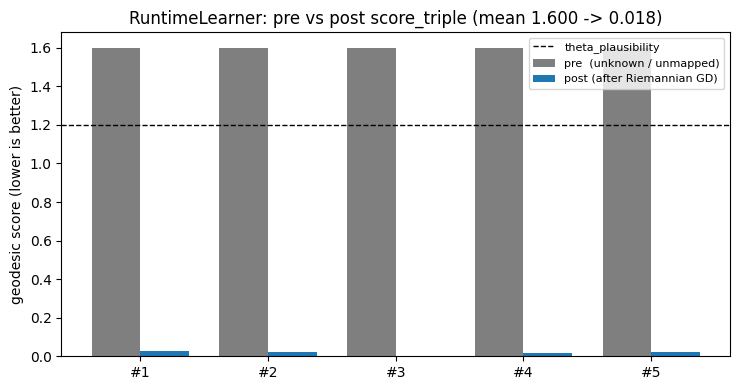

In [7]:
# Visualization: pre/post score_triple per added triple
import matplotlib.pyplot as plt
import numpy as np

labels = [f'#{i+1}' for i in range(len(new_triples))]
x = np.arange(len(labels))
width = 0.38

fig, ax = plt.subplots(figsize=(7.5, 4.0))
ax.bar(x - width/2, scores_before, width,
       label='pre  (unknown / unmapped)',
       color='tab:gray')
ax.bar(x + width/2, scores_after,  width,
       label='post (after Riemannian GD)',
       color='tab:blue')
ax.axhline(1.2, color='black', linestyle='--', linewidth=1,
           label='theta_plausibility')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('geodesic score (lower is better)')
ax.set_title('RuntimeLearner: pre vs post score_triple '
             f'(mean {pre_mean:.3f} -> {post_mean:.3f})')
ax.legend(loc='upper right', fontsize=8)
fig.tight_layout()
plt.show()


### Exercises

1. Re-run with `n_steps=50` (the default) and compare the post-training mean.  Does it still fall below the $\theta = 1.2$ threshold, or does it stall in the irrelevance band?
2. Add a contradicting triple — for example `(iris_dataset_v2, has_n_rows, 9999)` — after the first write.  Confirm that the contradiction gate rejects it via the `is_functional` schema rule (or, if the corpus did not declare `has_n_rows` functional, accepts it and explain why the gate could not catch the conflict).
3. Inspect `learner.training_status()` mid-flight by splitting the `learn_triples` and `wait_for_training` calls into separate cells.  What does the status string report while Phase 2 is running?

### What you should now be able to do

- Construct a `RuntimeLearner` with a non-default   `LearnConfig(n_steps=...)`.
- Queue a batch of new triples and pull Phase 2 to   completion via `flush_training` and   `wait_for_training`.
- Read pre/post `score_triple` to confirm that the new   triples actually moved onto the manifold.
- Recognise the cap-trained relation expansion bug and   prefer pre-injecting seed triples when the model has   `cap_enabled = True`.

### Cross-references

- USER_GUIDE.md section 13 (Runtime learning)
- `docgms/learn.py:RuntimeLearner.learn_triples` and   `RuntimeLearner._expand_rotors`
- `gms_agent_builder_ext/chapters/ch08.tex §8.3` for the   runtime growth protocol in book form
- §4.1 `score_triple` — how the geodesic baseline used   here is computed.

In [8]:
# Final assertion: post-training mean should drop
# vs the pre-training baseline.
# TODO(p7-execute): set absolute threshold once observed
assert post_mean < pre_mean, (
    f'expected post-mean < pre-mean; got '
    f'pre={pre_mean:.4f} vs post={post_mean:.4f}'
)
print(f'OK: post-mean {post_mean:.4f} < '
      f'pre-mean {pre_mean:.4f}; '
      f'RuntimeLearner converged on {len(new_triples)} '
      f'new triples in {learn_cfg.n_steps} steps.')


OK: post-mean 0.0179 < pre-mean 1.6000; RuntimeLearner converged on 5 new triples in 200 steps.
